saved the figure


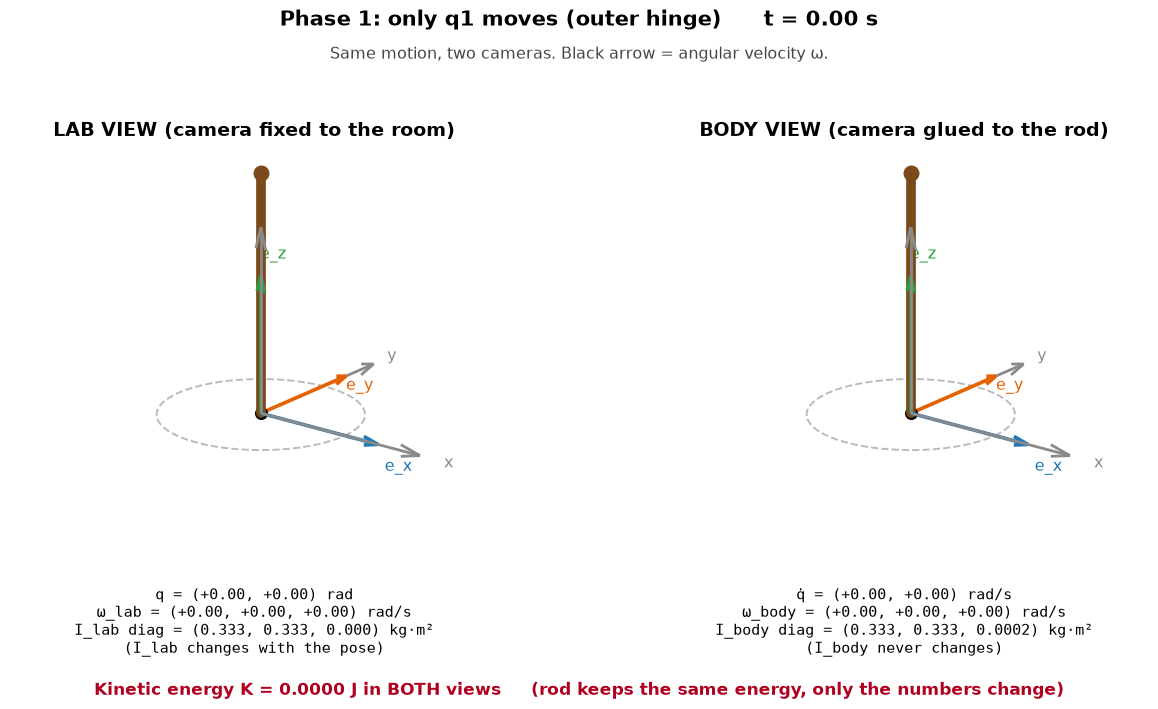

In [1]:
import os
import sys
from datetime import datetime

import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore
from matplotlib.animation import FuncAnimation, PillowWriter  # type: ignore

RESULT_DIR = os.path.join(os.getcwd(), "result")
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

# ---------------------------------------------------------------
# STEP 1: the gimbal rod and its inertia (body axes)
#   What we have: rod m = 1 kg, L = 1 m, r = 0.02 m, two hinges at the pivot
#                 outer hinge about lab x_hat (angle q1), inner hinge about a2 = Rx(q1) y_hat (angle q2)
#   What we want: I about the pivot in the rod's own axes
#   Why: constant and diagonal in body axes
#   I_pivot = m L^2/12 + m (L/2)^2,  I_zz = m r^2/2
# ---------------------------------------------------------------
M_ROD, L_ROD, R_ROD = 1.0, 1.0, 0.02
I_PIV = M_ROD * L_ROD**2 / 12 + M_ROD * (L_ROD / 2) ** 2
I_ZZ = M_ROD * R_ROD**2 / 2
I_BODY = np.diag([I_PIV, I_PIV, I_ZZ])

# ---------------------------------------------------------------
# STEP 2: a prescribed motion q1(t), q2(t) in three phases (smoothstep)
#   What we have: start (0, 0)
#   What we want: phase 1 only q1 moves, phase 2 only q2 moves, phase 3 both move
#   Why: each phase shows a different part of the lab to body translation
#   q(t) = q_start + (q_end - q_start) s(u),  s(u) = 3u^2 - 2u^3,  u = (t - t0)/T
# ---------------------------------------------------------------
PHASES = [  # (name, T seconds, q1 end, q2 end)
    ("Phase 1: only q1 moves (outer hinge)", 3.0, 0.9, 0.0),
    ("Phase 2: only q2 moves (inner hinge)", 3.0, 0.9, 0.9),
    ("Phase 3: both hinges move", 4.0, -0.6, -0.7),
]
FPS = 16
q_start = np.array([0.0, 0.0])
segments = []
t0 = 0.0
for name, T, q1e, q2e in PHASES:
    segments.append((name, t0, T, q_start.copy(), np.array([q1e, q2e])))
    q_start = np.array([q1e, q2e])
    t0 += T
T_TOTAL = t0


def q_and_qdot(t):
    for name, ts, T, qa, qb in segments:
        if t <= ts + T + 1e-12:
            u = np.clip((t - ts) / T, 0.0, 1.0)
            s, ds = 3 * u**2 - 2 * u**3, (6 * u - 6 * u**2) / T
            return name, qa + (qb - qa) * s, (qb - qa) * ds
    name, ts, T, qa, qb = segments[-1]
    return name, qb, np.zeros(2)


def Rx(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])


def Ry(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])


# ---------------------------------------------------------------
# STEP 3: everything at each time
#   What we have: q, qdot
#   What we want: R, omega in both views, K in both views
#   Why: the animation shows the same numbers the lesson derives
#   R = Rx(q1) Ry(q2) = [e_x e_y e_z],  omega_lab = q1dot x_hat + q2dot a2,  omega_body = R^T omega_lab
#   I_lab = R I_body R^T,  K = 1/2 omega_lab^T I_lab omega_lab = 1/2 omega_body^T I_body omega_body
#   Body view = apply V = R^T to every vector of the lab view (lab view: V = identity)
# ---------------------------------------------------------------
N_FRAMES = int(T_TOTAL * FPS) + 1
TIMES = np.linspace(0.0, T_TOTAL, N_FRAMES)
TH = np.linspace(0, 2 * np.pi, 80)
RING_R = 0.42


def state(t):
    name, q, qd = q_and_qdot(t)
    R = Rx(q[0]) @ Ry(q[1])
    a2 = Rx(q[0]) @ np.array([0.0, 1.0, 0.0])
    w_lab = qd[0] * np.array([1.0, 0, 0]) + qd[1] * a2
    w_body = R.T @ w_lab
    I_lab = R @ I_BODY @ R.T
    K_lab = 0.5 * w_lab @ I_lab @ w_lab
    K_body = 0.5 * w_body @ I_BODY @ w_body
    assert abs(K_lab - K_body) < 1e-9
    ring = RING_R * (np.outer(np.cos(TH), [1.0, 0, 0]) + np.outer(np.sin(TH), a2))
    return dict(name=name, q=q, qd=qd, R=R, w_lab=w_lab, w_body=w_body, I_lab=I_lab, K=K_lab, ring=ring)


STATES = [state(t) for t in TIMES]
TIP_LAB = np.array([s["R"][:, 2] * L_ROD for s in STATES])  # rod tip in the room
UP_BODY = np.array([s["R"].T @ np.array([0.0, 0, 1.0]) for s in STATES])  # room's up seen from the rod

# ---------------------------------------------------------------
# STEP 4: draw
#   What we have: the states
#   What we want: left panel = room camera (V = identity), right panel = rod camera (V = R^T)
#   Why: same motion, two points of view
# ---------------------------------------------------------------
GRAY, BLUE, ORANGE, GREEN, BROWN, RED = "#8a8a8a", "#1f77b4", "#e66100", "#2a9d3f", "#7a4a1a", "#b00020"
fig = plt.figure(figsize=(13, 7.4))
ax_l = fig.add_axes((0.00, 0.20, 0.50, 0.66), projection="3d")
ax_b = fig.add_axes((0.50, 0.20, 0.50, 0.66), projection="3d")
sup = fig.text(0.5, 0.965, "", ha="center", va="top", fontsize=15, fontweight="bold")
sub = fig.text(0.5, 0.915, "Same motion, two cameras. Black arrow = angular velocity ω.", ha="center", va="top",
               fontsize=11.5, color="#444444")
txt_l = fig.text(0.25, 0.185, "", ha="center", va="top", fontsize=10.5, family="monospace")
txt_b = fig.text(0.75, 0.185, "", ha="center", va="top", fontsize=10.5, family="monospace")
txt_k = fig.text(0.5, 0.045, "", ha="center", va="center", fontsize=12.5, fontweight="bold", color=RED)


def draw(ax, V, st, trace, title, frame):
    ax.cla()
    ax.set_axis_off()
    ax.set_xlim(-0.75, 0.75)
    ax.set_ylim(-0.75, 0.75)
    ax.set_zlim(-0.35, 1.1)
    ax.set_box_aspect((1.5, 1.5, 1.45), zoom=1.28)
    ax.view_init(elev=18, azim=-52)
    ax.set_title(title, fontsize=13.5, fontweight="bold", y=0.96)
    R = st["R"]
    pairs = [(V @ np.array([1.0, 0, 0]), "x", GRAY, 0.78), (V @ np.array([0, 1.0, 0]), "y", GRAY, 0.78),
             (V @ np.array([0, 0, 1.0]), "z", GRAY, 0.78),
             (V @ R[:, 0], "e_x", BLUE, 0.58), (V @ R[:, 1], "e_y", ORANGE, 0.58), (V @ R[:, 2], "e_z", GREEN, 0.58)]
    for v, lab, col, sc in pairs:
        ax.quiver(0, 0, 0, *(sc * v), color=col, linewidth=2.0 if col == GRAY else 2.6, arrow_length_ratio=0.12)
        off = np.array([0, 0, -0.07]) if lab in ("e_x", "e_y") else (np.array([0.06, 0, 0]) if lab == "e_z" else 0)
        ax.text(*(1.17 * sc * v + off), lab, color=col, fontsize=11.5, ha="center", va="center")
    ring = (V @ st["ring"].T).T
    ax.plot(ring[:, 0], ring[:, 1], ring[:, 2], color="#bbbbbb", lw=1.4, ls="--")
    tip = V @ R[:, 2] * L_ROD
    ax.plot([0, tip[0]], [0, tip[1]], [0, tip[2]], color=BROWN, lw=7, solid_capstyle="round", zorder=5)
    ax.scatter(*tip, s=110, color=BROWN, zorder=6)
    ax.scatter(0, 0, 0, s=70, color="black", zorder=7)
    if trace is not None and frame > 1:
        ax.plot(trace[: frame + 1, 0], trace[: frame + 1, 1], trace[: frame + 1, 2], color="#c9a26b", lw=1.6)
    w = V @ (st["w_lab"])
    if np.linalg.norm(w) > 1e-6:
        ax.quiver(0, 0, 0, *(0.2 * w), color="black", linewidth=4.2, arrow_length_ratio=0.22)


def update(i):
    st = STATES[i]
    V_lab = np.eye(3)
    V_body = st["R"].T
    draw(ax_l, V_lab, st, TIP_LAB, "LAB VIEW (camera fixed to the room)", i)
    # body view: the whole picture is multiplied by R^T, so the rod stays still and the room rotates
    draw(ax_b, V_body, st, None, "BODY VIEW (camera glued to the rod)", i)
    sup.set_text(f"{st['name']}      t = {TIMES[i]:.2f} s")
    wl, wb, Il = st["w_lab"], st["w_body"], st["I_lab"]
    txt_l.set_text(f"q = ({st['q'][0]:+.2f}, {st['q'][1]:+.2f}) rad\n"
                   f"ω_lab = ({wl[0]:+.2f}, {wl[1]:+.2f}, {wl[2]:+.2f}) rad/s\n"
                   f"I_lab diag = ({Il[0, 0]:.3f}, {Il[1, 1]:.3f}, {Il[2, 2]:.3f}) kg·m²\n"
                   f"(I_lab changes with the pose)")
    txt_b.set_text(f"q̇ = ({st['qd'][0]:+.2f}, {st['qd'][1]:+.2f}) rad/s\n"
                   f"ω_body = ({wb[0]:+.2f}, {wb[1]:+.2f}, {wb[2]:+.2f}) rad/s\n"
                   f"I_body diag = ({I_PIV:.3f}, {I_PIV:.3f}, {I_ZZ:.4f}) kg·m²\n"
                   f"(I_body never changes)")
    txt_k.set_text(f"Kinetic energy K = {st['K']:.4f} J in BOTH views     "
                   f"(rod keeps the same energy, only the numbers change)")


# ---------------------------------------------------------------
# STEP 5: save a still for checking, then the animation
#   Why: check the layout before rendering all frames
# ---------------------------------------------------------------
if len(sys.argv) > 1 and sys.argv[1] == "still":
    update(int(0.8 * N_FRAMES))
    out = os.path.join(RESULT_DIR, f"lab_vs_body_still_{TIMESTAMP}.png")
    fig.savefig(out, dpi=110)
    print("saved the figure")
else:
    anim = FuncAnimation(fig, update, frames=N_FRAMES, interval=1000 / FPS)
    out = os.path.join(RESULT_DIR, f"lab_vs_body_animation_{TIMESTAMP}.gif")
    anim.save(out, writer=PillowWriter(fps=FPS), dpi=75)
    print("saved the figure")